[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/0_use_a_builtin_encoder.ipynb)

# Use an encoder that is already fitted

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Load an encoder of the paper (Inception or ResNet-50, fitted to macaque V1 or V4), predict neural responses to images and compute its Fisher information metric J(x). An encoder is a frozen backbone plus a readout fitted to neural data.

* **Requirements**: `pip install multigeom scikit-image` and a connection (checkpoint and backbone weights are downloaded the first time). A CPU is enough.

* **Time**: about 10 s.

* **Next**: notebook 1 builds an encoder from scratch.

## 1. Setup

In [ ]:
# on Google Colab install the package from PyPI, without its dependencies: Colab already has
# torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom

In [1]:
# move to the repository root (the folder containing environment.yml): data/ and runs/ are read from there
import os
from pathlib import Path

root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent
if (root / "environment.yml").exists():
    os.chdir(root)
print("working folder:", Path.cwd())

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")      # no download progress bars in the notebook

import matplotlib.pyplot as plt
import torch
from matplotlib.patches import Circle
from PIL import Image
from skimage import data as skdata       # three public-domain photos that ship with scikit-image

import multigeom
from multigeom import compute_fisher, load_encoder, validate_encoder
from multigeom.datasets import CANONICAL_TRANSFORM

device = "cuda" if torch.cuda.is_available() else "cpu"
print("multigeom", multigeom.__version__, "| device:", device)

working folder: /home/steeve/steeve/idv/code/multigeom-tutorials
multigeom 1.0.0 | device: cuda


## 2. Load an encoder of the paper

`load_encoder(name, area)` downloads the checkpoint from the [Hugging Face repository](https://huggingface.co/steevelaquitaine/multigeom) the first time (it is cached afterwards) and returns the encoder in evaluation mode. The checkpoints of the paper are:

| `name` | backbone (frozen, ImageNet weights) | `area` |
|---|---|---|
| `"inception"` | InceptionV3, cut after `Conv2d_4a_3x3` | `"V1"` or `"V4"` |
| `"resnet50"` | ResNet-50, cut after `layer1.0` | `"V1"` or `"V4"` |

Every encoder predicts the 50 most reliable neurons of its area. You can also pass the path of a checkpoint saved on disk: `load_encoder("path/to/encoder.pt")` (notebook 1 does that).

In [2]:
encoder = load_encoder("inception", area="V1", device=device)
print(encoder.summary())

InceptionEncoder: backbone InceptionBackbone (out [C=192, 12, 12]), readout GaussianReadout, 50 neurons, 9,800 trainable / 182,472 parameters


`summary()` names the parts. Only the readout is trainable: the backbone keeps its pretrained weights. The attributes `encoder.backbone` and `encoder.readout` are ordinary PyTorch modules, and `encoder.n_neurons` is the number of predicted neurons.

In [3]:
print("backbone output (channels, height, width):", encoder.backbone.out_channels, "x", encoder.backbone.out_spatial, "x", encoder.backbone.out_spatial)
print("readout:", type(encoder.readout).__name__, "| neurons:", encoder.n_neurons)
print("trainable parameters:", sum(p.numel() for p in encoder.parameters() if p.requires_grad))

backbone output (channels, height, width): 192 x 12 x 12
readout: GaussianReadout | neurons: 50
trainable parameters: 9800


### What the readout learned

Each neuron looks at the feature map through a Gaussian window with a centre `mu` and a width `sigma`, in coordinates where the image spans [-1, 1]. The circles below are the windows of the 50 V1 neurons, drawn on the example photo below (centres and widths, not to scale of the true receptive fields).

images: (3, 1, 64, 64) range -1.0 to 0.9843137264251709


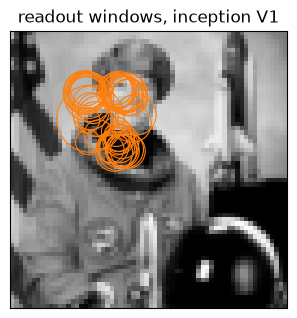

In [4]:
def to_input(photo):
    """Centre-crop a photo to a square and convert it to the canonical input: [1, 64, 64], grayscale, in [-1, 1]."""
    img = Image.fromarray(photo)
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return CANONICAL_TRANSFORM(img.crop((left, top, left + s, top + s)).convert("RGB"))


photos = {"astronaut": skdata.astronaut(), "cat": skdata.chelsea(), "coffee": skdata.coffee()}
images = torch.stack([to_input(p) for p in photos.values()])       # [3, 1, 64, 64] in [-1, 1]
print("images:", tuple(images.shape), "range", float(images.min()), "to", float(images.max()))

mu, sigma = encoder.readout.mu.detach().cpu(), encoder.readout.sigma.detach().cpu().abs()
fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.imshow(images[0, 0], cmap="gray", extent=(-1, 1, 1, -1), vmin=-1, vmax=1)
for (x, y), s in zip(mu.tolist(), sigma.tolist()):
    ax.add_patch(Circle((x, y), s, fill=False, color="tab:orange", lw=0.8))
ax.set_xlim(-1, 1); ax.set_ylim(1, -1); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("readout windows, inception V1")
plt.show()

## 3. Predict neural responses

`encoder.predict(images)` returns the predicted responses, one row per image and one column per neuron. It takes images of shape `[N, 1, 64, 64]` with values in `[-1, 1]` (the canonical input: 64 x 64 pixels, one grey channel), runs in batches in evaluation mode without gradients, and returns a CPU tensor. It also accepts a dataset or a data loader.

responses: (3, 50) (images x neurons)


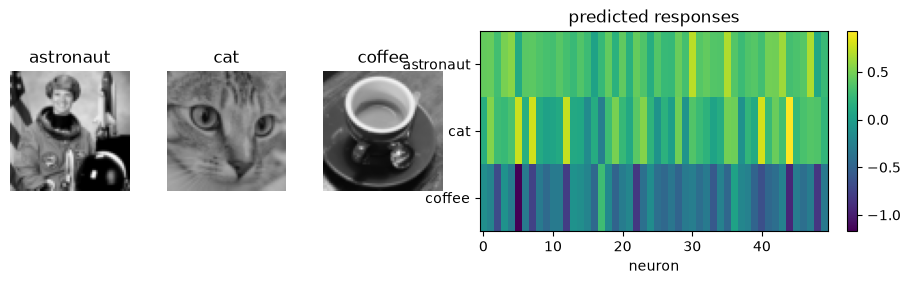

In [5]:
responses = encoder.predict(images)
print("responses:", tuple(responses.shape), "(images x neurons)")

fig, axes = plt.subplots(1, 4, figsize=(11, 2.6), gridspec_kw={"width_ratios": [1, 1, 1, 3.2]})
for ax, (name, _), x in zip(axes, photos.items(), images):
    ax.imshow(x[0], cmap="gray", vmin=-1, vmax=1); ax.set_title(name); ax.axis("off")
im = axes[3].imshow(responses, aspect="auto", cmap="viridis")
axes[3].set_yticks(range(3)); axes[3].set_yticklabels(photos); axes[3].set_xlabel("neuron")
axes[3].set_title("predicted responses")
fig.colorbar(im, ax=axes[3], fraction=0.04)
plt.show()

## 4. Compute the Fisher information metric J(x)

The encoder follows the *encoder contract* (a differentiable function from an image to responses), so every tool of the package accepts it. `validate_encoder` checks the contract and names the rule that a model breaks. `compute_fisher` returns the top eigenvalues and eigenvectors of the Fisher information $J(x)=\frac{1}{\sigma^2}J_f(x)^\top J_f(x)$ at one image, where $J_f$ is the Jacobian of the responses with respect to the pixels and $\sigma$ the noise of the neurons. The leading eigenvectors are the image changes that move the predicted responses the most.

contract satisfied: 50 neurons, response std 0.12 | warnings: none
eigenvalues: ['176', '115', '50.3', '35.7']


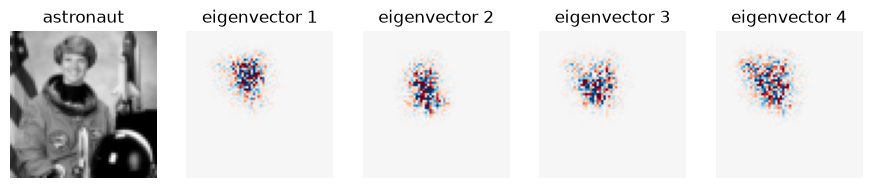

In [6]:
report = validate_encoder(encoder, sigma=0.22)
print("contract satisfied:", report.n_neurons, "neurons, response std", round(report.response_std, 2), "| warnings:", report.warnings or "none")

fisher = compute_fisher(image=images[:1], encoder=encoder, sigma=0.22, top_k=4, device=torch.device(device))
print("eigenvalues:", [f"{v:.3g}" for v in fisher.eigenvalues.tolist()])

fig, axes = plt.subplots(1, 5, figsize=(11, 2.5))
axes[0].imshow(images[0, 0], cmap="gray", vmin=-1, vmax=1); axes[0].set_title("astronaut")
for k, ax in enumerate(axes[1:]):
    v = fisher.eigenvectors[k].reshape(64, 64).cpu()
    m = v.abs().quantile(0.99)
    ax.imshow(v, cmap="RdBu_r", vmin=-m, vmax=m); ax.set_title(f"eigenvector {k + 1}")
for ax in axes: ax.axis("off")
plt.show()

## 5. The other encoders of the paper

The same four lines work for every checkpoint. Each one predicts the same 50-neuron format for its area, from its own backbone.

In [7]:
for name in ("inception", "resnet50"):
    for area in ("V1", "V4"):
        enc = load_encoder(name, area=area)
        out = enc.predict(images)
        print(f"{name:9s} {area}: predicts {tuple(out.shape)} | {enc.summary().split(': ', 1)[1]}")

inception V1: predicts (3, 50) | backbone InceptionBackbone (out [C=192, 12, 12]), readout GaussianReadout, 50 neurons, 9,800 trainable / 182,472 parameters
inception V4: predicts (3, 50) | backbone InceptionBackbone (out [C=192, 12, 12]), readout GaussianReadout, 50 neurons, 9,800 trainable / 182,472 parameters
resnet50  V1: predicts (3, 50) | backbone ResNet50Backbone (out [C=256, 16, 16]), readout GaussianReadout, 50 neurons, 13,000 trainable / 97,544 parameters
resnet50  V4: predicts (3, 50) | backbone ResNet50Backbone (out [C=256, 16, 16]), readout GaussianReadout, 50 neurons, 13,000 trainable / 97,544 parameters


## Recap

| To do | Call |
|---|---|
| load an encoder of the paper | `load_encoder("inception", area="V1")` |
| load a checkpoint from disk | `load_encoder("path/to/encoder.pt")` |
| predict neural responses | `encoder.predict(images)` |
| check the encoder contract | `multigeom.validate_encoder(encoder)` |
| Fisher information of one image | `multigeom.compute_fisher(image=x, encoder=encoder, sigma=0.22)` |

**Next**: [notebook 1](1_create_your_encoder.ipynb) builds an encoder of your own, fits it to neural data, saves it and loads it back.